In [40]:
import os, time, re, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, ConfusionMatrixDisplay

In [41]:
# GPU/ CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Đang dùng:", device)

Đang dùng: cuda


In [42]:
#DATA_PATH = os.path.join("..", "data", "IMDB Dataset.csv")
DATA_PATH = "/content/IMDB Dataset.csv"
RESULTS_PATH = "results.csv"

SEED = 42
SAMPLE_SIZE = None # số review dùng để chạy (None = dùng cả 50k)
VOCAB_SIZE = 10000
MAX_LEN = 128

D_MODEL = 128 # embedding dim
D_FF = 256
N_LAYERS = 2
DROPOUT = 0.1

BATCH_SIZE = 64
LR = 5e-4
EPOCHS = 5


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [43]:
df = pd.read_csv(DATA_PATH)
df["label"] = (df["sentiment"] == "positive").astype(int) # positive = 1, negative = 0

if SAMPLE_SIZE:
    df = df.sample(SAMPLE_SIZE, random_state=SEED)

# 80% train, 10% val, 10% test (giữ nguyên tỉ lệ positive/negative)
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED)

print("train / val / test:", len(train_df), len(val_df), len(test_df))

train / val / test: 40000 5000 5000


In [44]:
def tokenize(text):
    text = text.lower().replace("<br />", " ")
    return re.findall(r"[a-z']+", text)


# Từ điển chỉ xây từ tập train. 0 = PAD, 1 = UNK
counter = Counter(w for text in train_df["review"] for w in tokenize(text))
vocab = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common(VOCAB_SIZE - 2)]
word2id = {w: i for i, w in enumerate(vocab)}


def encode(text):
    return [word2id.get(w, 1) for w in tokenize(text)]


# Lưu danh sách id đầy đủ (chưa cắt/pad) để thử nhiều max_length
train_ids = [encode(t) for t in train_df["review"]]
val_ids = [encode(t) for t in val_df["review"]]
test_ids = [encode(t) for t in test_df["review"]]


def make_loader(ids_list, labels, max_len, shuffle):
    # Cắt về max_len, pad bằng 0
    X = np.zeros((len(ids_list), max_len), dtype=np.int64)
    for i, ids in enumerate(ids_list):
        ids = ids[:max_len]
        X[i, :len(ids)] = ids
    dataset = TensorDataset(torch.from_numpy(X), torch.tensor(labels, dtype=torch.long))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle)


def get_loaders(max_len):
    return (make_loader(train_ids, train_df["label"].values, max_len, True),
            make_loader(val_ids, val_df["label"].values, max_len, False),
            make_loader(test_ids, test_df["label"].values, max_len, False))

### Model: Transformer và LSTM

In [45]:
def positional_encoding(max_len, d_model):
    pos = torch.arange(max_len).unsqueeze(1) # (max_len, 1)
    i = torch.arange(0, d_model, 2) # 0, 2, 4, ...
    angle = pos / (10000 ** (i / d_model)) # (max_len, d_model/2)
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(angle)
    pe[:, 1::2] = torch.cos(angle)
    return pe


class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, d_ff, n_layers, max_len, dropout, pooling="mean"):
        super().__init__()
        self.pooling = pooling # "mean" hoặc "cls"
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model)) # vector [CLS] học được
        self.register_buffer("pe", positional_encoding(max_len + 1, d_model))
        layer = nn.TransformerEncoderLayer(d_model, n_heads, d_ff, dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.fc = nn.Linear(d_model, 2)

    def embed_input(self, x):
        # Embedding + Positional Encoding
        return self.embedding(x) + self.pe[:x.size(1)]

    def forward(self, x):
        pad_mask = (x == 0) # True ở vị trí PAD
        h = self.embedding(x)

        if self.pooling == "cls":
            # Thêm [CLS] vào đầu câu (không bị mask)
            cls = self.cls_token.expand(x.size(0), -1, -1)
            h = torch.cat([cls, h], dim=1)
            pad_mask = torch.cat([torch.zeros_like(pad_mask[:, :1]), pad_mask], dim=1)

        h = self.encoder(h + self.pe[:h.size(1)], src_key_padding_mask=pad_mask)

        if self.pooling == "cls":
            pooled = h[:, 0] # lấy vector tại [CLS]
        else:
            # Mean pooling, bỏ qua PAD
            mask = (~pad_mask).unsqueeze(-1).float()
            pooled = (h * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.fc(pooled)


class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 2)

    def forward(self, x):
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(
            self.embedding(x), lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed) # h_n: (1, B, hidden)
        return self.fc(h_n[-1])

In [46]:
def evaluate(model, loader):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total_loss, y_true, y_pred = 0, [], []
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            total_loss += loss_fn(logits, y).item()
            y_true += y.tolist()
            y_pred += logits.argmax(dim=1).tolist()
    return total_loss / len(y_true), y_true, y_pred


def train_and_test(model, name, loaders):
    train_loader, val_loader, test_loader = loaders
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss()
    train_losses, val_losses = [], []

    start = time.time()
    for epoch in range(EPOCHS):
        model.train()
        total, n = 0, 0
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(X), y)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(y)
            n += len(y)
        val_loss, _, _ = evaluate(model, val_loader)
        train_losses.append(total / n)
        val_losses.append(val_loss)
        print(f"[{name}] epoch {epoch + 1}/{EPOCHS} - train loss {total / n:.4f} - val loss {val_loss:.4f}")
    train_time = time.time() - start

    _, y_true, y_pred = evaluate(model, test_loader)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary")
    return {
        "model": model,
        "parameters": sum(p.numel() for p in model.parameters()),
        "train_time": train_time,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "train_losses": train_losses,
        "val_losses": val_losses,
    }


def save_result(experiment, config, r):
    row = pd.DataFrame([{
        "experiment": experiment,
        "config": config,
        "parameters": r["parameters"],
        "train_time_s": round(r["train_time"], 1),
        "accuracy": round(r["accuracy"], 4),
        "precision": round(r["precision"], 4),
        "recall": round(r["recall"], 4),
        "f1": round(r["f1"], 4),
    }])
    row.to_csv(RESULTS_PATH, mode="a", header=not os.path.exists(RESULTS_PATH), index=False)

### 19. Experiment 2: Số lượng attention heads

In [47]:
loaders = get_loaders(MAX_LEN)
runs_heads = {}
rows = []

for h in [1, 2, 4, 8]:
    set_seed()
    model = TransformerClassifier(VOCAB_SIZE, D_MODEL, h, D_FF, N_LAYERS, MAX_LEN, DROPOUT)
    r = train_and_test(model, f"{h} heads", loaders)
    runs_heads[h] = r
    save_result("exp2_heads", f"heads={h}, d_k={D_MODEL // h}", r)
    rows.append({"Heads": h, "d_k": D_MODEL // h, "Parameters": r["parameters"],
                 "Training time (s)": round(r["train_time"], 1),
                 "Accuracy": round(r["accuracy"], 4), "F1": round(r["f1"], 4)})

pd.DataFrame(rows)

[1 heads] epoch 1/5 - train loss 0.5428 - val loss 0.4647
[1 heads] epoch 2/5 - train loss 0.4070 - val loss 0.3797
[1 heads] epoch 3/5 - train loss 0.3520 - val loss 0.3752
[1 heads] epoch 4/5 - train loss 0.3139 - val loss 0.3624
[1 heads] epoch 5/5 - train loss 0.2734 - val loss 0.3712
[2 heads] epoch 1/5 - train loss 0.5356 - val loss 0.4517
[2 heads] epoch 2/5 - train loss 0.3974 - val loss 0.3954
[2 heads] epoch 3/5 - train loss 0.3455 - val loss 0.3763
[2 heads] epoch 4/5 - train loss 0.3077 - val loss 0.3790
[2 heads] epoch 5/5 - train loss 0.2662 - val loss 0.3829
[4 heads] epoch 1/5 - train loss 0.5212 - val loss 0.4256
[4 heads] epoch 2/5 - train loss 0.3927 - val loss 0.3822
[4 heads] epoch 3/5 - train loss 0.3417 - val loss 0.3769
[4 heads] epoch 4/5 - train loss 0.3019 - val loss 0.3759
[4 heads] epoch 5/5 - train loss 0.2598 - val loss 0.3796
[8 heads] epoch 1/5 - train loss 0.5145 - val loss 0.4118
[8 heads] epoch 2/5 - train loss 0.3838 - val loss 0.3770
[8 heads] epoc

,Heads,d_k,Parameters,Training time (s),Accuracy,F1
0,1,128,1545346,44.1,0.8438,0.8401
1,2,64,1545346,44.9,0.8384,0.8381
2,4,32,1545346,48.2,0.8398,0.8374
3,8,16,1545346,54.4,0.8406,0.8399


### 20. Experiment 3: Visualize attention của từng head

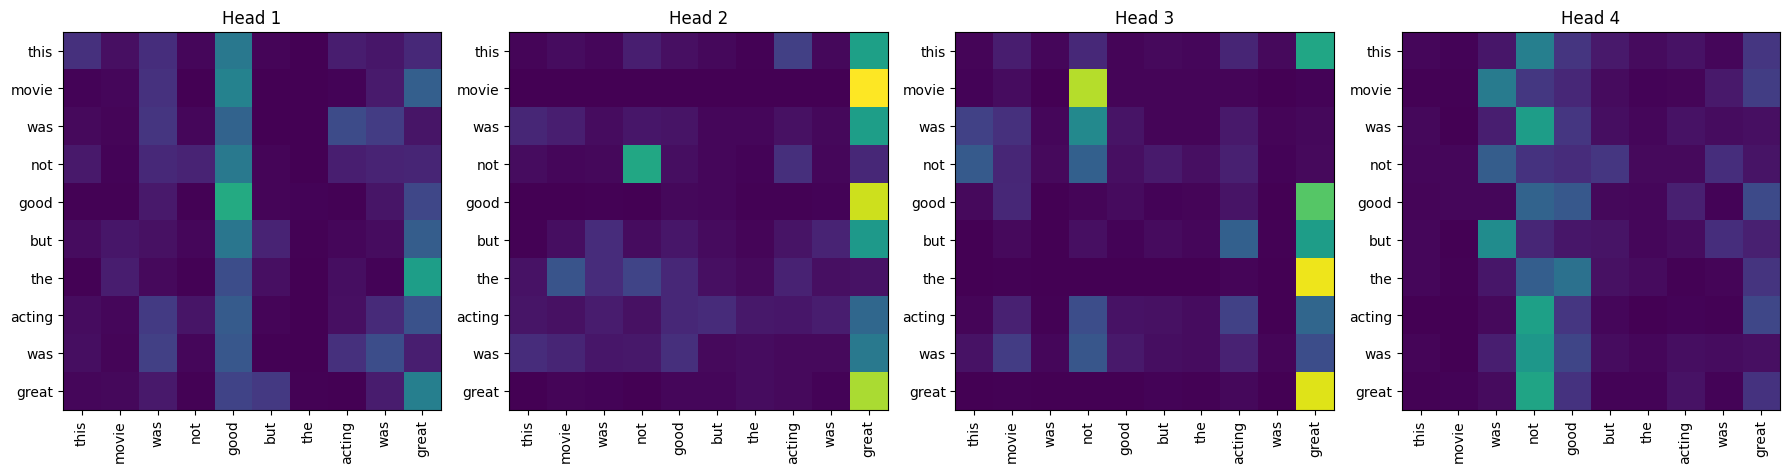

In [48]:
model = runs_heads[4]["model"]
model.eval()

sentence = "this movie was not good but the acting was great"
tokens = tokenize(sentence)
ids = torch.tensor([[word2id.get(w, 1) for w in tokens]]).to(device) # (1, T)

with torch.no_grad():
    x = model.embed_input(ids) # (1, T, d_model)
    first_layer = model.encoder.layers[0]
    # need_weights=True và average_attn_weights=False để lấy attention của từng head
    _, attn = first_layer.self_attn(x, x, x, need_weights=True, average_attn_weights=False)
attn = attn[0].cpu().numpy() # (n_heads, T, T)

n_heads = attn.shape[0]
fig, axes = plt.subplots(1, n_heads, figsize=(4.5 * n_heads, 4.5))
for i, ax in enumerate(axes):
    ax.imshow(attn[i], cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"Head {i + 1}")
    ax.set_xticks(range(len(tokens)))
    ax.set_yticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=90)
    ax.set_yticklabels(tokens)
plt.tight_layout()
plt.savefig("attention_heads.png", dpi=150)
plt.show()

In [49]:
# Mô tả bằng số: head nào tập trung, head nào phân tán, các head có giống nhau không
T = len(tokens)
entropy = -(attn * np.log(attn + 1e-9)).sum(axis=-1).mean(axis=-1)      # mỗi head 1 giá trị
print(f"Entropy trung bình của từng head (thấp = tập trung, cao nhất = {np.log(T):.2f} = đều):")
for i, e in enumerate(entropy):
    print(f"  Head {i + 1}: {e:.3f}")

# Độ khác nhau giữa từng cặp head (càng gần 0 càng giống nhau / có thể dư thừa)
diff = np.zeros((n_heads, n_heads))
for i in range(n_heads):
    for j in range(n_heads):
        diff[i, j] = np.abs(attn[i] - attn[j]).mean()
print("\nSai khác trung bình giữa các cặp head:")
print(pd.DataFrame(diff.round(4), index=[f"H{i + 1}" for i in range(n_heads)],
                   columns=[f"H{i + 1}" for i in range(n_heads)]))

Entropy trung bình của từng head (thấp = tập trung, cao nhất = 2.30 = đều):
  Head 1: 1.613
  Head 2: 1.302
  Head 3: 1.177
  Head 4: 1.585

Sai khác trung bình giữa các cặp head:
        H1      H2      H3      H4
H1  0.0000  0.1172  0.1284  0.1067
H2  0.1172  0.0000  0.0868  0.1262
H3  0.1284  0.0868  0.0000  0.1246
H4  0.1067  0.1262  0.1246  0.0000


### 21. Experiment 4: Transformer vs LSTM
Cùng dataset, split, vocabulary, embedding dim, batch size, optimizer, learning rate, số epochs.
- Model A: Embedding → LSTM → Classifier
- Model B: Embedding + Positional Encoding → Transformer Encoder → Mean pooling → Classifier (dùng lại kết quả 4 heads ở Experiment 2, cùng cấu hình và seed)

In [50]:
set_seed()
lstm = LSTMClassifier(VOCAB_SIZE, D_MODEL, D_MODEL)
r_lstm = train_and_test(lstm, "LSTM", loaders)
r_trans = runs_heads[4]

save_result("exp4_lstm_vs_transformer", "LSTM", r_lstm)
save_result("exp4_lstm_vs_transformer", "Transformer (4 heads)", r_trans)

pd.DataFrame([
    {"Model": name, "Parameters": r["parameters"], "Training time (s)": round(r["train_time"], 1),
     "Accuracy": round(r["accuracy"], 4), "Precision": round(r["precision"], 4),
     "Recall": round(r["recall"], 4), "F1": round(r["f1"], 4)}
    for name, r in [("LSTM", r_lstm), ("Transformer", r_trans)]
])

[LSTM] epoch 1/5 - train loss 0.6566 - val loss 0.6404
[LSTM] epoch 2/5 - train loss 0.5910 - val loss 0.5812
[LSTM] epoch 3/5 - train loss 0.6231 - val loss 0.4970
[LSTM] epoch 4/5 - train loss 0.4676 - val loss 0.4692
[LSTM] epoch 5/5 - train loss 0.4066 - val loss 0.4357


,Model,Parameters,Training time (s),Accuracy,Precision,Recall,F1
0,LSTM,1412354,30.0,0.7934,0.8099,0.7668,0.7878
1,Transformer,1545346,48.2,0.8398,0.8503,0.8248,0.8374


### 22. Experiment 5: Sequence length


In [51]:
avg_len = np.mean([len(ids) for ids in train_ids])
rows = []

for L in [32, 64, 128, 256]:
    set_seed()
    model = TransformerClassifier(VOCAB_SIZE, D_MODEL, 4, D_FF, N_LAYERS, L, DROPOUT)
    r = train_and_test(model, f"max_len={L}", get_loaders(L))

    # % token giữ lại sau khi cắt về L token
    kept = np.mean([min(len(ids), L) for ids in train_ids]) / avg_len
    # Bộ nhớ attention: batch x heads x T x T số float32 (4 byte), tính cho 1 layer
    attn_mb = BATCH_SIZE * 4 * L * L * 4 / 1e6

    save_result("exp5_seq_length", f"max_len={L}, tokens_kept={kept:.1%}, attn_mem_MB={attn_mb:.1f}", r)
    rows.append({"Length": L, "Tokens retained": f"{kept:.1%}", "Attention matrix (T^2)": L * L,
                 "Attention memory (MB/batch/layer)": round(attn_mb, 1),
                 "Training time (s)": round(r["train_time"], 1), "F1": round(r["f1"], 4)})

pd.DataFrame(rows)

[max_len=32] epoch 1/5 - train loss 0.6115 - val loss 0.5603
[max_len=32] epoch 2/5 - train loss 0.5316 - val loss 0.5412
[max_len=32] epoch 3/5 - train loss 0.4852 - val loss 0.5460
[max_len=32] epoch 4/5 - train loss 0.4415 - val loss 0.5426
[max_len=32] epoch 5/5 - train loss 0.3927 - val loss 0.5839
[max_len=64] epoch 1/5 - train loss 0.5697 - val loss 0.5152
[max_len=64] epoch 2/5 - train loss 0.4681 - val loss 0.4680
[max_len=64] epoch 3/5 - train loss 0.4169 - val loss 0.4791
[max_len=64] epoch 4/5 - train loss 0.3710 - val loss 0.4734
[max_len=64] epoch 5/5 - train loss 0.3246 - val loss 0.5248
[max_len=128] epoch 1/5 - train loss 0.5212 - val loss 0.4256
[max_len=128] epoch 2/5 - train loss 0.3927 - val loss 0.3822
[max_len=128] epoch 3/5 - train loss 0.3417 - val loss 0.3769
[max_len=128] epoch 4/5 - train loss 0.3019 - val loss 0.3759
[max_len=128] epoch 5/5 - train loss 0.2598 - val loss 0.3796
[max_len=256] epoch 1/5 - train loss 0.4854 - val loss 0.3809
[max_len=256] epoc

,Length,Tokens retained,Attention matrix (T^2),Attention memory (MB/batch/layer),Training time (s),F1
0,32,13.9%,1024,1.0,23.3,0.7313
1,64,27.5%,4096,4.2,27.7,0.7767
2,128,51.8%,16384,16.8,48.3,0.8374
3,256,77.2%,65536,67.1,107.8,0.8591


### 23. Application: Transformer text classification
Pipeline: Raw text → Tokenizer → Token IDs → Embedding → Positional Encoding → Transformer Encoder → Mean pooling → Linear classifier → Prediction

In [52]:
main_model = runs_heads[4]["model"]


def predict(text, model=main_model):
    # Raw text -> token ids -> model -> xác suất
    ids = encode(text)[:MAX_LEN] or [1] # câu rỗng thì dùng <unk>
    x = torch.tensor([ids]).to(device)
    model.eval()
    with torch.no_grad():
        prob = torch.softmax(model(x), dim=1)[0]
    label = "Positive" if prob[1] > 0.5 else "Negative"
    return label, prob[1].item() # P(positive)


label, p = predict("I really enjoyed this movie.")
print("Input : I really enjoyed this movie.")
print("Output:", label)
print(f"Probability (positive): {p:.4f}")

Input : I really enjoyed this movie.
Output: Positive
Probability (positive): 0.9923


### Thử các loại câu: ngắn, dài, negation, contrast, ambiguous

In [53]:
long_review = (
    "I went into this movie with low expectations because the trailer looked generic, and for the first "
    "twenty minutes I thought I was right. But slowly the story found its feet, the characters became "
    "people I genuinely cared about, and the final act was both surprising and moving. The acting is "
    "wonderful across the board, the music fits every scene, and the director clearly trusted the "
    "audience. I would happily watch it again."
)

samples = [
    ("short", "Great movie!"),
    ("short", "Terrible."),
    ("long", long_review),
    ("negation", "This movie is not good."),
    ("negation", "I can't say I disliked it."),
    ("contrast", "The acting was great, but the story was boring and far too long."),
    ("contrast", "The plot is weak, however the acting and the music are excellent."),
    ("ambiguous", "It was okay, I guess."),
    ("ambiguous", "Some parts were amazing and others were terrible."),
]

rows = []
for kind, text in samples:
    label, p = predict(text)
    rows.append({"Type": kind, "Text": text[:70] + ("..." if len(text) > 70 else ""),
                 "Prediction": label, "P(positive)": round(p, 4)})
pd.DataFrame(rows)

,Type,Text,Prediction,P(positive)
0,short,Great movie!,Positive,0.9974
1,short,Terrible.,Negative,0.0017
2,long,I went into this movie with low expectations b...,Positive,0.9325
3,negation,This movie is not good.,Positive,0.7998
4,negation,I can't say I disliked it.,Positive,0.9942
5,contrast,"The acting was great, but the story was boring...",Negative,0.2403
6,contrast,"The plot is weak, however the acting and the m...",Positive,0.8776
7,ambiguous,"It was okay, I guess.",Negative,0.2998
8,ambiguous,Some parts were amazing and others were terrible.,Positive,0.9693


### Chạy trên tập test của IMDB và lưu dự đoán (dùng cho error analysis)

In [54]:
def predict_proba(model, loader):
    # P(positive) cho từng review trong loader (loader không shuffle nên giữ nguyên thứ tự)
    model.eval()
    probs = []
    with torch.no_grad():
        for X, _ in loader:
            probs += torch.softmax(model(X.to(device)), dim=1)[:, 1].cpu().tolist()
    return np.array(probs)


test_loader = loaders[2]
test_results = test_df[["review", "label"]].reset_index(drop=True)
test_results["prob_pos"] = predict_proba(main_model, test_loader)
test_results["pred"] = (test_results["prob_pos"] > 0.5).astype(int)
test_results["correct"] = test_results["pred"] == test_results["label"]
test_results["n_tokens"] = [len(ids) for ids in test_ids]
test_results["truncated"] = test_results["n_tokens"] > MAX_LEN # review dài hơn MAX_LEN bị cắt

print("Số review test:", len(test_results))
print("Dự đoán đúng :", test_results["correct"].sum())
print("Dự đoán sai  :", (~test_results["correct"]).sum())
print("Accuracy     :", round(test_results["correct"].mean(), 4))
test_results.head()

Số review test: 5000
Dự đoán đúng : 4199
Dự đoán sai  : 801
Accuracy     : 0.8398


,review,label,prob_pos,pred,correct,n_tokens,truncated
0,"Although it has been 2 years, I still remember...",0,0.034438,0,True,133,True
1,"THE BLOB is a great horror movie, not merely b...",1,0.061282,0,False,489,True
2,The saddest thing about this film is that only...,1,0.900585,1,True,472,True
3,WARNING! This review will reveal the ending of...,0,0.034150,0,True,628,True
4,This is a film that has garnered any interest ...,0,0.223756,0,True,132,True


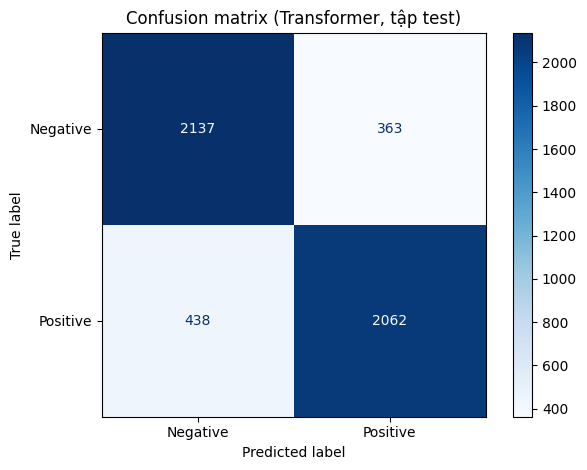

In [55]:
# Confusion matrix trên tập test
ConfusionMatrixDisplay.from_predictions(
    test_results["label"], test_results["pred"],
    display_labels=["Negative", "Positive"], cmap="Blues")
plt.title("Confusion matrix (Transformer, tập test)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

### 25. Experiment 6: Mean pooling vs CLS-style pooling

In [56]:
set_seed()
model_cls = TransformerClassifier(VOCAB_SIZE, D_MODEL, 4, D_FF, N_LAYERS, MAX_LEN, DROPOUT, pooling="cls")
r_cls = train_and_test(model_cls, "CLS pooling", loaders)
r_mean = runs_heads[4]

save_result("exp6_pooling", "mean pooling, heads=4", r_mean)
save_result("exp6_pooling", "cls-style pooling, heads=4", r_cls)

pd.DataFrame([
    {"Pooling": name, "Accuracy": round(r["accuracy"], 4), "F1": round(r["f1"], 4),
     "Training time (s)": round(r["train_time"], 1)}
    for name, r in [("Mean", r_mean), ("CLS-style", r_cls)]
])

[CLS pooling] epoch 1/5 - train loss 0.5302 - val loss 0.4320
[CLS pooling] epoch 2/5 - train loss 0.4085 - val loss 0.4070
[CLS pooling] epoch 3/5 - train loss 0.3578 - val loss 0.3835
[CLS pooling] epoch 4/5 - train loss 0.3176 - val loss 0.3762
[CLS pooling] epoch 5/5 - train loss 0.2803 - val loss 0.3831


,Pooling,Accuracy,F1,Training time (s)
0,Mean,0.8398,0.8374,48.2
1,CLS-style,0.8326,0.8287,55.0


### 29. Learning curves

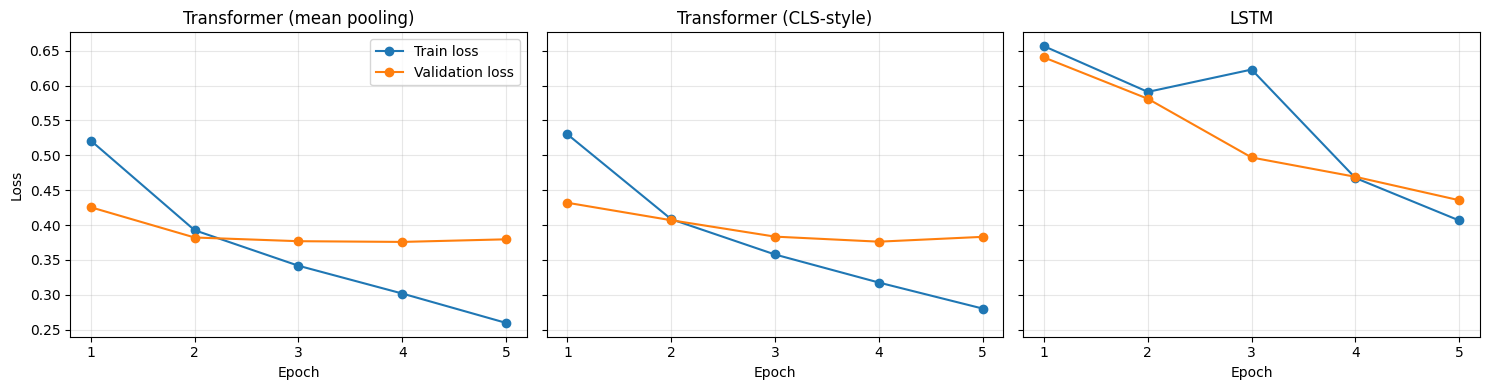

In [59]:
curve_runs = {"Transformer (mean pooling)": r_mean,
              "Transformer (CLS-style)": r_cls,
              "LSTM": r_lstm}

fig, axes = plt.subplots(1, len(curve_runs), figsize=(5 * len(curve_runs), 4), sharey=True)
for ax, (name, r) in zip(axes, curve_runs.items()):
    epochs = range(1, len(r["train_losses"]) + 1)
    ax.plot(epochs, r["train_losses"], marker="o", label="Train loss")
    ax.plot(epochs, r["val_losses"], marker="o", label="Validation loss")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epochs))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Loss")
axes[0].legend()
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150)
plt.show()

In [58]:
# Số liệu để nhận xét overfitting / underfitting / convergence / instability
for name, r in curve_runs.items():
    train_l, val_l = r["train_losses"], r["val_losses"]
    best_epoch = int(np.argmin(val_l)) + 1
    print(f"{name}")
    print(f"  Train loss: {train_l[0]:.3f} -> {train_l[-1]:.3f} | Val loss: {val_l[0]:.3f} -> {val_l[-1]:.3f}")
    print(f"  Val loss thấp nhất ở epoch {best_epoch}/{len(val_l)}", end="")
    print("  (val loss tăng lại sau đó -> dấu hiệu overfitting)" if best_epoch < len(val_l) else "  (vẫn đang giảm)")

Transformer (mean pooling)
  Train loss: 0.521 -> 0.260 | Val loss: 0.426 -> 0.380
  Val loss thấp nhất ở epoch 4/5  (val loss tăng lại sau đó -> dấu hiệu overfitting)
Transformer (CLS-style)
  Train loss: 0.530 -> 0.280 | Val loss: 0.432 -> 0.383
  Val loss thấp nhất ở epoch 4/5  (val loss tăng lại sau đó -> dấu hiệu overfitting)
LSTM
  Train loss: 0.657 -> 0.407 | Val loss: 0.640 -> 0.436
  Val loss thấp nhất ở epoch 5/5  (vẫn đang giảm)
